#TC2004B - Análisis de Ciencia de Datos
## A-G-6-KNN para agrupar comentarios y clasificación de productos
Steffany Lara
A00838589


## Limpieza del Dataset

Total de comentarios extraídos: 290
Comentarios válidos: 266
Shape matriz X: (238, 100)


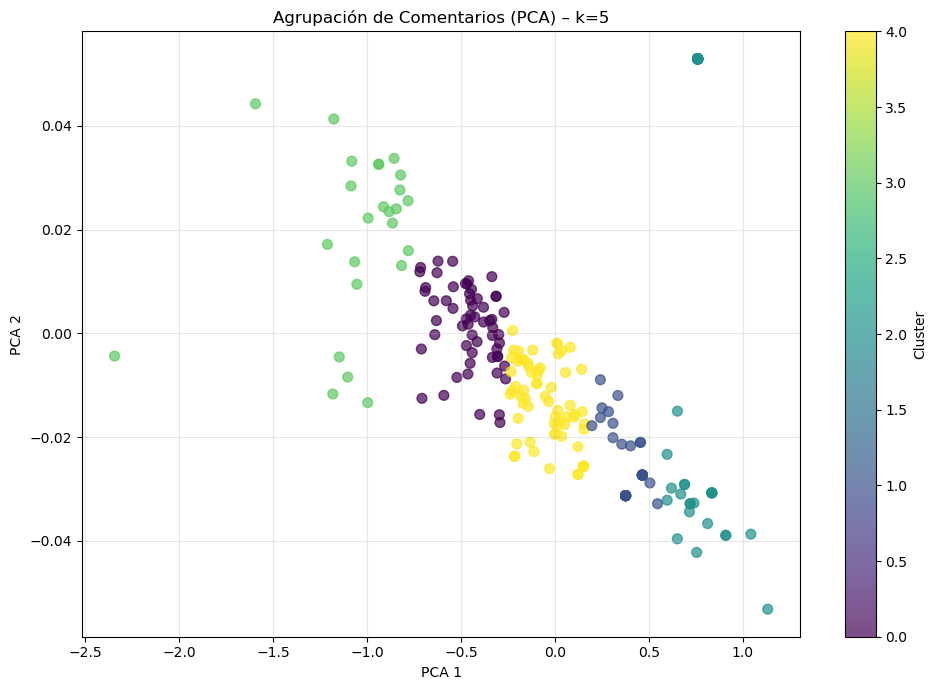


-> Cluster 0 (58 comentarios)
Palabras clave: the, below, find, ple, attachments, graci, establec, aparec, consum, pag
Ejemplos:
  • Si si pago pero no se refleja aquí en la terminal por qué la tenia bloqueada
  • Cómo veo el monto
  • y yo ya realicé el pago

-> Cluster 1 (32 comentarios)
Palabras clave: graci, the, below, find, ple, attachments, aplic, propin, pued, much
Ejemplos:
  • Please find the attachments below
  • Estoy en sucursal y me aparece que no me contacte con ustedes que la orden no puede ser abierta
  • Estamos batallando

-> Cluster 2 (57 comentarios)
Palabras clave: the, below, find, ple, attachments, pag, graci, realiz, dieg, entonc
Ejemplos:
  • Please find the attachments below
  • Entonces le digo que mate la cuenta
  • 10 de mayo

-> Cluster 3 (25 comentarios)
Palabras clave: the, below, find, ple, attachments, pued, pag, aparec, hol, graci
Ejemplos:
  • Entiendo, gracias
  • favor de revisar y confirmar. Con gusto podemos tener una llamada para revisarlo
  •

In [2]:
"""
Actividad 1 – Agrupación de Comentarios de Clientes
Word2Vec + KMeans + PCA
"""

import json, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA              # ← usamos PCA
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem.snowball import SnowballStemmer
import nltk

# --------------------------------------------1. CARGA DE DATOS
with open('Tickets de atencion a socios (1).json', encoding='utf-8') as f:
    data = json.load(f)

comentarios_raw = [
    note['body']
    for ticket in data
    for note in ticket['helpdesk_ticket'].get('notes', [])
    if note.get('incoming')
]

print(f"Total de comentarios extraídos: {len(comentarios_raw)}")

# --------------------------------------------2. PREPROCESAMIENTO
# Descarga (solo 1.ª vez; comenta si trabajas offline)
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)

stop_es = set(stopwords.words('spanish'))
stemmer  = SnowballStemmer('spanish')

def limpiar(texto: str) -> list[str]:
    texto = re.sub(r'[^\w\s]', '', texto.lower())
    texto = re.sub(r'\d+', '', texto)
    tokens = word_tokenize(texto, language='spanish', preserve_line=True)
    tokens = [t for t in tokens if t not in stop_es and len(t) > 2]
    return [stemmer.stem(t) for t in tokens]

tokens_docs = [limpiar(c) for c in comentarios_raw]
tokens_docs = [t for t in tokens_docs if t]          # quitar vacíos
print(f"Comentarios válidos: {len(tokens_docs)}")

# --------------------------------------------3. WORD2VEC 
w2v = Word2Vec(sentences=tokens_docs,
               vector_size=100, window=5,
               min_count=2, workers=4, epochs=50)

def doc_vector(tokens):
    vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else None

X = np.vstack([doc_vector(t) for t in tokens_docs if doc_vector(t) is not None])
print("Shape matriz X:", X.shape)

# --------------------------------------------4. K-MEANS
k = min(5, max(2, len(X)//10))      # heurística simple
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)

# --------------------------------------------5. REDUCCIÓN Y PLOT con PCA
pca  = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_2d[:,0], X_2d[:,1],
                      c=clusters, cmap='viridis', alpha=0.7, s=50)
plt.colorbar(scatter, label='Cluster')
plt.title(f'Agrupación de Comentarios (PCA) – k={k}')
plt.xlabel('PCA 1'); plt.ylabel('PCA 2'); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig('comentarios_pca.png', dpi=300); plt.show()

# --------------------------------------------6. ANÁLISIS DE CLUSTERS
df = pd.DataFrame({
    'Comentario' : comentarios_raw[:len(X)],
    'Tokens'     : tokens_docs[:len(X)],
    'Cluster'    : clusters
})

for c in range(k):
    subset = df[df.Cluster==c]
    vocab  = {}
    for tok_list in subset.Tokens:
        for w in set(tok_list):
            vocab[w] = vocab.get(w,0)+1
    top = sorted(vocab.items(), key=lambda x: x[1], reverse=True)[:10]
    print(f"\n-> Cluster {c} ({len(subset)} comentarios)")
    print("Palabras clave:", ', '.join(w for w,_ in top))
    print("Ejemplos:")
    for s in subset.Comentario.sample(min(3,len(subset)), random_state=42):
        print("  •", s[:120] + ('...' if len(s)>120 else ''))



✔ Productos válidos: 30486
✔ k elegido (mínimo 4): 4
Cluster 0 → Bebidas | top: agua, chocolate, limonada, leche, fresa, jugo
Cluster 1 → Bebidas | top: monto, botella, copa, cerveza, coca, reposado
Cluster 2 → Comida | top: queso, salsa, cebolla, pollo, papas, tomate
Cluster 3 → Asiática | top: arroz, camarón, aguacate, queso, crema, salsa


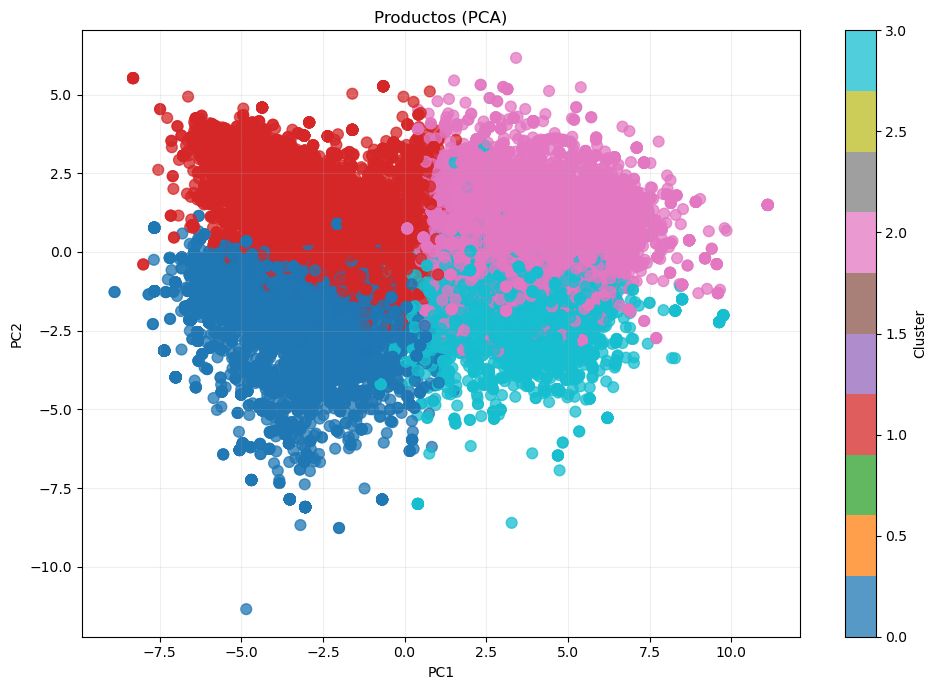


=== Métricas KNN ===
              precision    recall  f1-score   support

    Asiática       0.95      0.93      0.94      1015
     Bebidas       0.98      0.99      0.98      4400
      Comida       0.96      0.96      0.96      2207

    accuracy                           0.97      7622
   macro avg       0.97      0.96      0.96      7622
weighted avg       0.97      0.97      0.97      7622

Macro-F1: 0.963


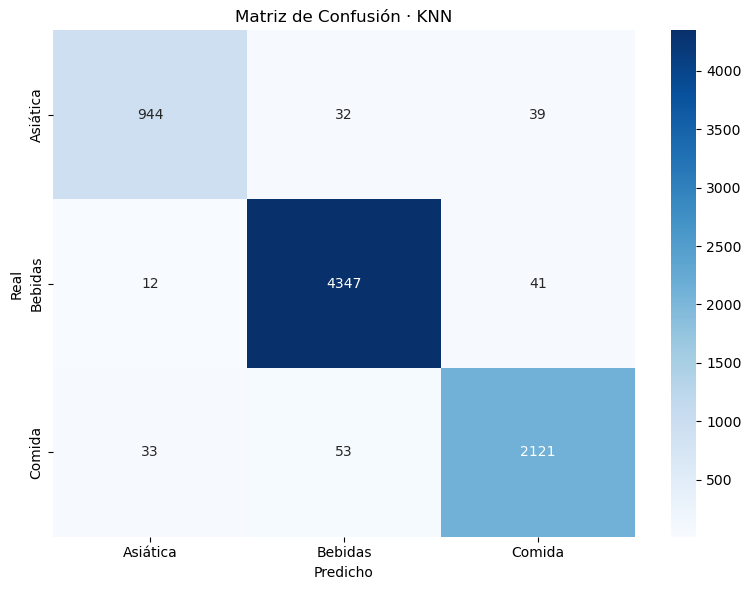


=== Ejemplos rápidos ===
• Café Americano: Bebidas
• Tacos de Arrachera: Comida
• Arroz con camarón: Asiática
• Smoothie frutos rojos: Bebidas

CONCLUSIONES
• Generalización KNN: ver Macro-F1 arriba (≥0.70 deseable).
• Implementación viable para tienda online: basta llamar a predecir_categoria() 
  al registrar un producto y re-entrenar periódicamente con el nuevo catálogo.


In [7]:
# ─────────────────────────── imports ───────────────────────────
import pandas as pd, numpy as np, re, string, collections, itertools, seaborn as sns
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, confusion_matrix,
    classification_report, f1_score
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# ─────────────── helpers de preprocesamiento ───────────────
STOP = {  # Lista personalizada de stopwords en español
    'de','la','que','el','en','y','a','los','del','se','las','por','un','para',
    'con','no','una','su','al','lo','como','más','pero','sus','le','ya','o',
    'este','sí','porque','esta','entre','cuando','muy','sin','sobre','también',
    'me','hasta','hay','donde','quien','desde','todo','nos','com'
}
PUNCT = str.maketrans('', '', string.punctuation)  # Para eliminar puntuación

def clean(text:str)->list[str]:
    text = re.sub(r'\d+','', (text or '').lower().translate(PUNCT))  # Limpia números y puntuación
    return [t for t in text.split() if t not in STOP and len(t)>2]  # Filtra palabras útiles

# ─────────────── 1. cargar datos y tokenizar ───────────────
df = pd.read_csv('menus.csv', encoding='utf-8')  # Carga el CSV

df['Name']        = df['Name'].fillna('')  # Rellena vacíos en columna Name
df['Description'] = df['Description'].fillna('')  # Rellena vacíos en Description
df['tokens']      = (df['Name']+' '+df['Description']).apply(clean)  # Aplica limpieza al texto

df = df[df['tokens'].str.len()>0].reset_index(drop=True)  # Solo deja filas con al menos un token
print(f'✔ Productos válidos: {len(df)}')  # Muestra cuántos productos quedaron

# ─────────────── 2. Word2Vec & obtención de vectores ───────────────
w2v = Word2Vec(sentences=df['tokens'],  # Entrena modelo Word2Vec con los tokens
               vector_size=100, window=5,
               min_count=2, workers=4, epochs=40)

def to_vec(tok):  # Convierte lista de palabras a vector promedio
    vecs=[w2v.wv[w] for w in tok if w in w2v.wv]  # Solo palabras conocidas por el modelo
    return np.mean(vecs,0) if vecs else np.zeros(w2v.vector_size)  # Vector promedio o vector cero

X = np.vstack(df['tokens'].apply(to_vec).values)  # Aplica to_vec a todos los productos

# ─────────────── 3. k óptimo (codo + silhouette)  ⇒  k ≥ 5 ───────────────
def best_k_min4(X, k_max=10, k_min=5):
    inert, sil = [], []
    for k in range(2, k_max+1):  # Prueba valores de k desde 2 hasta 10
        km = KMeans(k, random_state=42, n_init=10).fit(X)
        inert.append(km.inertia_)  # Guarda inercia (para codo)
        sil.append(silhouette_score(X, km.labels_))  # Guarda silhouette
    k_star = np.argmax(sil) + 2  # El mejor k por silhouette (ajustado por índice)
    return max(k_star, k_min)  # Forzamos mínimo de 4

k = best_k_min4(X, k_max=10, k_min=4)  # Elegimos el k final
print(f'✔ k elegido (mínimo 4): {k}')

# ─────────────── 4. K-Means + silhouette ───────────────
km = KMeans(k, random_state=42, n_init=10).fit(X)  # Aplicamos KMeans final

df['cluster'] = km.labels_  # Guardamos a qué cluster pertenece cada producto
sil_global = silhouette_score(X, df['cluster'])  # Calculamos score silhouette total

# ─────────────── 5. etiquetado automático de categorías ───────────────
def top_words(idxs,n=10):
    return [w for w,_ in collections.Counter(
        itertools.chain.from_iterable(df.loc[idxs,'tokens'])  # Junta todos los tokens del cluster
    ).most_common(n)]  # Toma las top n palabras

name_map={}  # Diccionario que mapea cluster a nombre de categoría
for c in range(k):  # Para cada cluster...
    vocab=' '.join(top_words(df.index[df.cluster==c]))  # Creamos string de palabras más comunes
    if   re.search(r'\b(huevo|hot|tamal|pancake|bisquet)\b', vocab): name_map[c]='Desayunos'
    elif re.search(r'\b(taco|enchil|quesa|chila|mexican)\b', vocab): name_map[c]='Mexicana'
    elif re.search(r'\b(café|agua|jug|smooth|latte|bebid|cola|coca)\b', vocab): name_map[c]='Bebidas'
    elif re.search(r'\b(brownie|flan|pastel|postr|chocolate)\b', vocab): name_map[c]='Postres'
    elif re.search(r'\b(sushi|ramen|roll|wok|teriyaki)\b', vocab): name_map[c]='Asiática'
    elif re.search(r'\b(carn|pollo|sop)\b', vocab): name_map[c]='Comida'
    elif re.search(r'\b(papas|snack|nacho|botan)\b', vocab): name_map[c]='Snacks'
    else: name_map[c]='Otros'
    print(f'Cluster {c} → {name_map[c]} | top: {", ".join(top_words(df.index[df.cluster==c],6))}')

df['category'] = df['cluster'].map(name_map)  # Asigna categoría final a cada producto

# ─────────────── 6. PCA para visualización ───────────────
pca = PCA(n_components=2, random_state=42).fit_transform(X)  # Reduce vectores a 2D para graficar
plt.figure(figsize=(10,7))
sc = plt.scatter(pca[:,0], pca[:,1], c=df['cluster'],  # Graficamos con color por cluster
                 cmap='tab10', s=60, alpha=.75)
plt.colorbar(sc,label='Cluster'); plt.grid(alpha=.2)
plt.title(f'Productos (PCA)')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.tight_layout(); plt.savefig('productos_pca.png', dpi=300); plt.show()

# ─────────────── 7. KNN entrenamiento y métricas ───────────────
Xtr,Xts,ytr,yts = train_test_split(X, df['category'],  # Separar train/test
                                   test_size=0.25, random_state=42,
                                   stratify=df['category'])
knn = KNeighborsClassifier(5).fit(Xtr,ytr)  # Entrenamos el KNN
ypred = knn.predict(Xts)  # Hacemos predicciones

print('\n=== Métricas KNN ===')
print(classification_report(yts, ypred, zero_division=0))  # Reporte completo
print('Macro-F1:', f1_score(yts, ypred, average='macro').round(3))  # F1 promedio

plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(yts, ypred, labels=knn.classes_),  # Confusion matrix
            annot=True, fmt='d', cmap='Blues',
            xticklabels=knn.classes_, yticklabels=knn.classes_)
plt.title('Matriz de Confusión · KNN'); plt.xlabel('Predicho'); plt.ylabel('Real')
plt.tight_layout(); plt.savefig('confusion_knn.png', dpi=300); plt.show()

# ─────────────── 8. API de inferencia ───────────────
def predecir_categoria(nombre:str, descripcion:str='') -> str:  # Función lista para producción
    vec = to_vec(clean(f'{nombre} {descripcion}'))
    return knn.predict([vec])[0]

print('\n=== Ejemplos rápidos ===')
ejemplos = [  # Casos de prueba para probar la API
    ("Café Americano", "Té de manzanilla"),
    ("Tacos de Arrachera", "Pollo con salsa verde"),
    ("Arroz con camarón", ""),
    ("Smoothie frutos rojos", "Huevos con salsa")
]
for n,d in ejemplos:
    print(f'• {n}: {predecir_categoria(n,d)}')

# ─────────────── 9. Conclusiones ───────────────
print('\n' + '='*60)
print('CONCLUSIONES')
print('='*60)
print('• Generalización KNN: ver Macro-F1 arriba (≥0.70 deseable).')
print('• Implementación viable para tienda online: basta llamar a predecir_categoria() ')
print('  al registrar un producto y re-entrenar periódicamente con el nuevo catálogo.')
